## 01 원본 로딩 및 구조

In [1]:
from pathlib import Path
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

DATASET_KEY = "서울특별시 마포구_담배꽁초 상습 투기지역 현황_20261105"

def find_repo():
    cwd = Path.cwd().resolve()
    for p in (cwd, *cwd.parents):
        if p.name == "do_not_lung" and (p / "notebooks").is_dir():
            return p
        candidate = p / "do_not_lung"
        if (candidate / "notebooks").is_dir():
            return candidate
    raise FileNotFoundError("do_not_lung 저장소를 찾을 수 없습니다.")

REPO = find_repo()
RAW_ROOT = REPO.parent / "data" / "raw_data"
OUT_DIR = REPO.parent / "data" / "processed_data" / DATASET_KEY
candidates = sorted(RAW_ROOT.rglob(DATASET_KEY + "*.csv"),
                    key=lambda p: (p.name != DATASET_KEY + ".csv", str(p)))
if not candidates:
    raise FileNotFoundError(f"원본 파일이 없습니다: {RAW_ROOT}")
RAW_PATH = candidates[0]
for encoding in ("utf-8-sig", "cp949", "euc-kr"):
    try:
        raw = pd.read_csv(RAW_PATH, encoding=encoding, dtype="string")
        break
    except UnicodeDecodeError:
        continue
else:
    raise UnicodeError("지원하는 인코딩으로 CSV를 해석하지 못했습니다.")
required = ["연번", "시도명", "시군구명", "도로명주소", "세부위치", "데이터기준일자"]
missing_req = set(required) - set(raw.columns)
if missing_req:
    raise ValueError(f"필수 컬럼이 누락됐습니다: {missing_req}")
raw_original_columns = raw.columns.tolist()
raw_memory_bytes = int(raw.memory_usage(index=True, deep=True).sum())
print("파일:", RAW_PATH.name, "인코딩:", encoding)
print("원본 shape:", raw.shape, "원본 메모리(bytes):", raw_memory_bytes)
print("컬럼:", raw_original_columns)
print("자료형:")
print(raw.dtypes.to_string())
display(raw.head(10))

파일: 서울특별시 마포구_담배꽁초 상습 투기지역 현황_20261105.csv 인코딩: cp949
원본 shape: (10, 7) 원본 메모리(bytes): 5215
컬럼: ['연번', '시도명', '시군구명', '도로명주소', '세부위치', '데이터기준일자', 'Unnamed: 6']
자료형:
연번            string
시도명           string
시군구명          string
도로명주소         string
세부위치          string
데이터기준일자       string
Unnamed: 6    string


,연번,시도명,시군구명,도로명주소,세부위치,데이터기준일자,Unnamed: 6
0,1.0,서울특별시,마포구,서울특별시 마포구 양화로 156,홍대입구역 9번출구 LG팰리스 뒤쪽 도로,2026-11-05,<NA>
1,2.0,서울특별시,마포구,서울특별시 마포구 양화로 183,홍대입구역 3번출구 인근,2026-11-05,<NA>
2,3.0,서울특별시,마포구,서울특별시 마포구 양화로 171,홍대입구역 2번출구 인근,2026-11-05,<NA>
3,4.0,서울특별시,마포구,서울특별시 마포구 양화로 36,할리스커피 인근,2026-11-05,<NA>
4,5.0,서울특별시,마포구,서울특별시 마포구 마포대로 89,마포우체국 앞쪽 도로,2026-11-05,<NA>
5,6.0,서울특별시,마포구,서울특별시 마포구 마포대로 144,마포T타운 뒤쪽 도로,2026-11-05,<NA>
6,7.0,서울특별시,마포구,서울특별시 마포구 상암산로 38,상암동 JTBC+KBS 건물 인근,2026-11-05,<NA>
7,8.0,서울특별시,마포구,서울특별시 마포구 잔다리로7안길,서현어린이집~GS25 서교명품점 도로구간,2026-11-05,<NA>
8,9.0,서울특별시,마포구,서울특별시 마포구 독막로 295,삼부골든타워 인근,2026-11-05,<NA>
9,10.0,서울특별시,마포구,서울특별시 마포구 성암로 301,한국지역정보개발원,2026-11-05,<NA>


## 02 품질 및 기초 통계

In [2]:
# 원본 값이 없는 후행 구분자 생성 컬럼만 제거한다.
trailing_empty_cols = [c for c in raw.columns
                       if c.startswith("Unnamed:") and raw[c].isna().all()]
base = raw.drop(columns=trailing_empty_cols).copy()
for col in base.columns:
    base[col] = base[col].astype("string").str.strip().replace("", pd.NA)
base.insert(0, "source_row_id", np.arange(1, len(base) + 1, dtype=int))
raw_dup = base.duplicated(subset=[c for c in base.columns if c != "source_row_id"], keep=False)
print("전체 행:", len(raw), "실제 정보 컬럼:", len(base.columns) - 1)
print("삭제한 정보 없는 컬럼:", trailing_empty_cols)
print("원본 동일 행(중복그룹에 포함되는 모든 행):", int(raw_dup.sum()))
print("시군구 분포:")
print(base["시군구명"].value_counts(dropna=False).to_string())
print("기준일 분포:")
print(base["데이터기준일자"].value_counts(dropna=False).to_string())
missing = pd.DataFrame({
    "column": base.columns,
    "missing_count": [int(base[c].isna().sum()) for c in base.columns],
    "missing_pct": [float(base[c].isna().mean() * 100) for c in base.columns]
})
display(missing)
print("중복 도로명주소 행:", int(base.duplicated("도로명주소", keep=False).sum()))
print("중복 세부위치 행:", int(base.duplicated("세부위치", keep=False).sum()))
print("고유 도로명주소:", base["도로명주소"].nunique())
print("고유 세부위치:", base["세부위치"].nunique())

전체 행: 10 실제 정보 컬럼: 6
삭제한 정보 없는 컬럼: ['Unnamed: 6']
원본 동일 행(중복그룹에 포함되는 모든 행): 0
시군구 분포:
시군구명
마포구    10
기준일 분포:
데이터기준일자
2026-11-05    10


,column,missing_count,missing_pct
0,source_row_id,0,0.0
1,연번,0,0.0
2,시도명,0,0.0
3,시군구명,0,0.0
4,도로명주소,0,0.0
5,세부위치,0,0.0
6,데이터기준일자,0,0.0


중복 도로명주소 행: 0
중복 세부위치 행: 0
고유 도로명주소: 10
고유 세부위치: 10


## 03 전처리 및 검증 플래그

In [3]:
clean = base.copy()
clean["serial_number"] = pd.to_numeric(clean["연번"], errors="coerce").astype("Float64")
clean["serial_valid_flag"] = (
    clean["serial_number"].notna()
    & clean["serial_number"].ge(1).fillna(False)
    & clean["serial_number"].mod(1).eq(0).fillna(False)
)
clean["reference_date_valid_flag"] = pd.to_datetime(
    clean["데이터기준일자"], format="%Y-%m-%d", errors="coerce"
).notna()
clean["데이터기준일자"] = pd.to_datetime(
    clean["데이터기준일자"], format="%Y-%m-%d", errors="coerce"
).dt.strftime("%Y-%m-%d").astype("string")
clean["is_mapo_district"] = (clean["시군구명"] == "마포구").fillna(False)
clean["address_district_match_flag"] = (
    clean["도로명주소"].str.contains("마포구", regex=False, na=False)
)
clean["duplicate_record_flag"] = raw_dup.astype(bool)
clean["duplicate_serial_flag"] = (
    clean["연번"].duplicated(keep=False) & clean["연번"].notna()
)
clean["duplicate_address_flag"] = (
    clean["도로명주소"].duplicated(keep=False) & clean["도로명주소"].notna()
)
clean["duplicate_location_detail_flag"] = (
    clean["세부위치"].duplicated(keep=False) & clean["세부위치"].notna()
)
# 주소에서 '도로명'과 건물 본번을 문자적으로 분리한다.
# 결번(도로구간)도 유효한 자료일 수 있으므로 임의로 도로주소를 채우지 않는다.
pattern = r"^서울특별시\s+마포구\s+(.+?)(?:\s+(\d+)(?:-(\d+))?)?$"
extracted = clean["도로명주소"].str.extract(pattern)
clean["road_name"] = extracted[0].astype("string")
clean["building_main_no"] = pd.to_numeric(extracted[1], errors="coerce").astype("Int64")
clean["building_sub_no"] = pd.to_numeric(extracted[2], errors="coerce").astype("Int64")
clean["has_building_number"] = clean["building_main_no"].notna()
clean["detail_char_length"] = clean["세부위치"].str.len().astype("Int64")
keyword_patterns = {
    "mentions_station": "역",
    "mentions_exit": "번출구",
    "mentions_nearby": "인근",
    "mentions_behind": "뒤쪽",
    "mentions_front": "앞쪽",
    "mentions_road_section": "도로구간",
    "mentions_childcare": "어린이집",
}
for flag, word in keyword_patterns.items():
    clean[flag] = clean["세부위치"].str.contains(word, regex=False, na=False)
clean["review_needed"] = (
    ~clean["serial_valid_flag"]
    | ~clean["reference_date_valid_flag"]
    | ~clean["is_mapo_district"]
    | ~clean["address_district_match_flag"]
    | clean["도로명주소"].isna()
    | clean["세부위치"].isna()
    | clean["duplicate_record_flag"]
    | clean["duplicate_serial_flag"]
)
print("전처리 전:", raw.shape, "정제 후:", clean.shape)
print("고유 도로명:", clean["road_name"].nunique(dropna=True))
print("건물번호 없는 주소(지점/구간 가능):", int((~clean["has_building_number"]).sum()))
print("검토 대상 행:", int(clean["review_needed"].sum()))
print("좌표 컬럼:", [c for c in clean.columns if c in ("위도", "경도", "geometry", "WKT")])
print("발생시각·적발건수 컬럼: 제공되지 않음")
display(clean.head(10))

전처리 전: (10, 7) 정제 후: (10, 29)
고유 도로명: 6
건물번호 없는 주소(지점/구간 가능): 1
검토 대상 행: 0
좌표 컬럼: []
발생시각·적발건수 컬럼: 제공되지 않음


,source_row_id,연번,시도명,시군구명,도로명주소,세부위치,데이터기준일자,serial_number,serial_valid_flag,reference_date_valid_flag,...,has_building_number,detail_char_length,mentions_station,mentions_exit,mentions_nearby,mentions_behind,mentions_front,mentions_road_section,mentions_childcare,review_needed
0,1,1.0,서울특별시,마포구,서울특별시 마포구 양화로 156,홍대입구역 9번출구 LG팰리스 뒤쪽 도로,2026-11-05,1.0,True,True,...,True,22,True,True,False,True,False,False,False,False
1,2,2.0,서울특별시,마포구,서울특별시 마포구 양화로 183,홍대입구역 3번출구 인근,2026-11-05,2.0,True,True,...,True,13,True,True,True,False,False,False,False,False
2,3,3.0,서울특별시,마포구,서울특별시 마포구 양화로 171,홍대입구역 2번출구 인근,2026-11-05,3.0,True,True,...,True,13,True,True,True,False,False,False,False,False
3,4,4.0,서울특별시,마포구,서울특별시 마포구 양화로 36,할리스커피 인근,2026-11-05,4.0,True,True,...,True,8,False,False,True,False,False,False,False,False
4,5,5.0,서울특별시,마포구,서울특별시 마포구 마포대로 89,마포우체국 앞쪽 도로,2026-11-05,5.0,True,True,...,True,11,False,False,False,False,True,False,False,False
5,6,6.0,서울특별시,마포구,서울특별시 마포구 마포대로 144,마포T타운 뒤쪽 도로,2026-11-05,6.0,True,True,...,True,11,False,False,False,True,False,False,False,False
6,7,7.0,서울특별시,마포구,서울특별시 마포구 상암산로 38,상암동 JTBC+KBS 건물 인근,2026-11-05,7.0,True,True,...,True,18,False,False,True,False,False,False,False,False
7,8,8.0,서울특별시,마포구,서울특별시 마포구 잔다리로7안길,서현어린이집~GS25 서교명품점 도로구간,2026-11-05,8.0,True,True,...,False,22,False,False,False,False,False,True,True,False
8,9,9.0,서울특별시,마포구,서울특별시 마포구 독막로 295,삼부골든타워 인근,2026-11-05,9.0,True,True,...,True,9,False,False,True,False,False,False,False,False
9,10,10.0,서울특별시,마포구,서울특별시 마포구 성암로 301,한국지역정보개발원,2026-11-05,10.0,True,True,...,True,9,True,False,False,False,False,False,False,False


## 04 기초통계 및 시각화

도로명별 등록 장소 수
road_name
양화로        4
마포대로       2
상암산로       1
잔다리로7안길    1
독막로        1
성암로        1
세부위치의 문자 키워드 포함 수 (중복 가능)
mentions_nearby          5
mentions_station         4
mentions_exit            3
mentions_behind          2
mentions_front           1
mentions_road_section    1
mentions_childcare       1
세부위치 길이 통계
count       10.0
mean        13.6
std      5.25357
min          8.0
25%          9.5
50%         12.0
75%        16.75
max         22.0


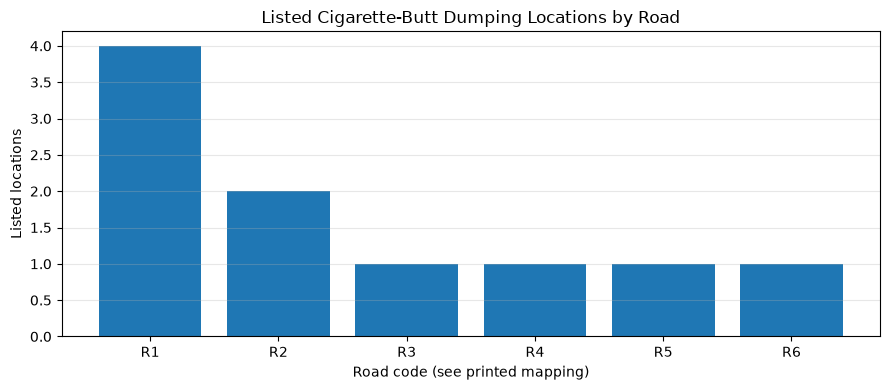

R1: 양화로
R2: 마포대로
R3: 상암산로
R4: 잔다리로7안길
R5: 독막로
R6: 성암로


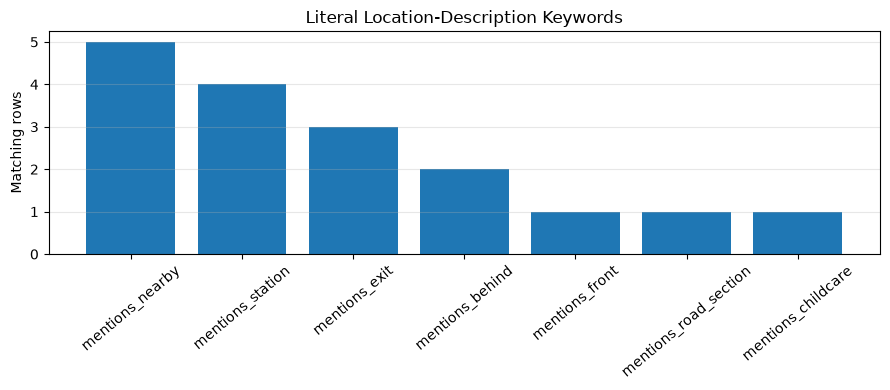

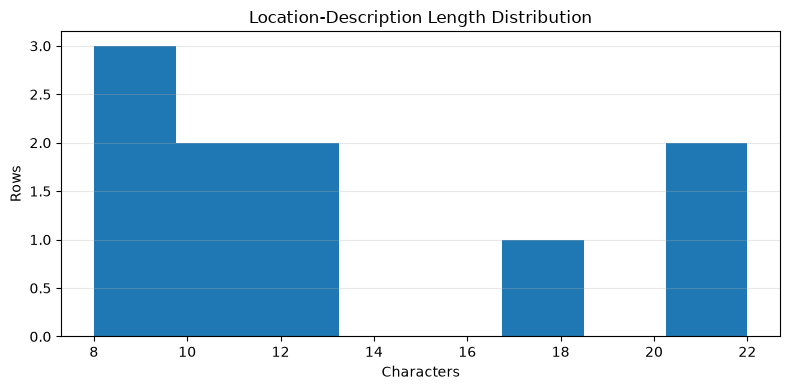

공간 분석: 위경도·WKT가 없어 지도 산점도/거리 분석을 생략함
시간 분석: 기준일자 1개뿐이며 실제 투기 시각은 제공되지 않음


In [4]:
road_counts = clean["road_name"].value_counts(dropna=False)
keyword_counts = pd.Series({
    flag: int(clean[flag].sum()) for flag in keyword_patterns
}).sort_values(ascending=False)
print("도로명별 등록 장소 수")
print(road_counts.to_string())
print("세부위치의 문자 키워드 포함 수 (중복 가능)")
print(keyword_counts.to_string())
print("세부위치 길이 통계")
print(clean["detail_char_length"].describe().to_string())
# 한국어 폰트가 없어도 확인 가능한 시각화와 코드-범주 매핑을 함께 제공한다.
fig, ax = plt.subplots(figsize=(9, 4))
road_codes = [f"R{i+1}" for i in range(len(road_counts))]
ax.bar(road_codes, road_counts.values)
ax.set_title("Listed Cigarette-Butt Dumping Locations by Road")
ax.set_xlabel("Road code (see printed mapping)")
ax.set_ylabel("Listed locations")
ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()
plt.close(fig)
for code, name in zip(road_codes, road_counts.index):
    print(f"{code}: {name}")
fig, ax = plt.subplots(figsize=(9, 4))
ax.bar(keyword_counts.index, keyword_counts.values)
ax.set_title("Literal Location-Description Keywords")
ax.set_ylabel("Matching rows")
ax.tick_params(axis="x", rotation=40)
ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()
plt.close(fig)
fig, ax = plt.subplots(figsize=(8, 4))
lengths = clean["detail_char_length"].dropna().astype(int)
ax.hist(lengths, bins=max(3, min(8, len(lengths))))
ax.set_title("Location-Description Length Distribution")
ax.set_xlabel("Characters")
ax.set_ylabel("Rows")
ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()
plt.close(fig)
print("공간 분석: 위경도·WKT가 없어 지도 산점도/거리 분석을 생략함")
print("시간 분석: 기준일자 1개뿐이며 실제 투기 시각은 제공되지 않음")

## 05 summary 및 features 생성

In [5]:
records = []
def add(section, metric, category, value, unit="", description=""):
    if pd.isna(value):
        value = np.nan
    records.append({
        "section": section,
        "metric": metric,
        "category": str(category),
        "value": value,
        "unit": unit,
        "description": description
    })
overall = {
    "raw_rows": (len(raw), "rows", "원본 행 수"),
    "raw_columns": (len(raw.columns), "columns", "원본 컬럼 수"),
    "clean_rows": (len(clean), "rows", "정제 후 행 수"),
    "clean_columns": (len(clean.columns), "columns", "정제 후 컬럼 수"),
    "unique_addresses": (clean["도로명주소"].nunique(), "addresses", "고유 도로명주소"),
    "unique_details": (clean["세부위치"].nunique(), "details", "고유 세부위치"),
    "unique_road_names": (clean["road_name"].nunique(), "roads", "추출된 고유 도로명"),
    "duplicate_record_rows": (int(clean["duplicate_record_flag"].sum()), "rows", "동일 정보 행 수"),
    "duplicate_address_rows": (int(clean["duplicate_address_flag"].sum()), "rows", "동일 주소 반복 행 수"),
    "invalid_serial_rows": (int((~clean["serial_valid_flag"]).sum()), "rows", "정수 양수 형식 연번 검증 실패"),
    "invalid_date_rows": (int((~clean["reference_date_valid_flag"]).sum()), "rows", "기준일자 파싱 실패"),
    "missing_building_number_rows": (int((~clean["has_building_number"]).sum()), "rows", "건물 본번이 없는 주소 - 위치 구간일 수 있음"),
    "review_needed_rows": (int(clean["review_needed"].sum()), "rows", "검토 필요 플래그 행"),
}
for metric, (value, unit, explanation) in overall.items():
    add("overall", metric, "", value, unit, explanation)
for c in raw.columns:
    add("missing_raw", "count", c, int(raw[c].isna().sum()), "rows", "원본 결측 행 수")
    add("missing_raw", "pct", c, float(raw[c].isna().mean()*100), "%", "원본 결측 비율")
for road, count in road_counts.items():
    add("road_name", "registered_locations", road if pd.notna(road) else "(결측)", int(count), "rows", "도로명별 등록 장소 수")
for word, count in keyword_counts.items():
    add("detail_keyword", "matching_rows", word, int(count), "rows", "세부위치 텍스트에 키워드가 포함된 행 수")
for date, count in clean["데이터기준일자"].value_counts(dropna=False).items():
    add("reference_date", "record_count", date if pd.notna(date) else "(결측)", int(count), "rows", "원본 기준일자별 행 수 (발생일 아님)")
for metric in ("min", "max", "mean", "median", "std"):
    add("description_length", metric, "detail_char_length", getattr(clean["detail_char_length"], metric)(), "characters", "세부위치 설명 문자열 길이 통계")
summary = pd.DataFrame(records)

# 행 단위 문자 파생변수 후보만 제공한다. 실제 사건 y 또는 공간좌표는 만들지 않는다.
feature_names = [
    "source_row_id", "연번", "시도명", "시군구명", "도로명주소", "세부위치", "데이터기준일자",
    "road_name", "building_main_no", "building_sub_no", "has_building_number",
    "detail_char_length", *keyword_patterns.keys(),
    "address_district_match_flag", "reference_date_valid_flag", "review_needed"
]
features = clean[feature_names].copy()
print("clean.csv:", clean.shape)
print("summary.csv:", summary.shape)
print("features.csv:", features.shape)
display(features.head(10))

clean.csv: (10, 29)
summary.csv: (46, 6)
features.csv: (10, 22)


,source_row_id,연번,시도명,시군구명,도로명주소,세부위치,데이터기준일자,road_name,building_main_no,building_sub_no,...,mentions_station,mentions_exit,mentions_nearby,mentions_behind,mentions_front,mentions_road_section,mentions_childcare,address_district_match_flag,reference_date_valid_flag,review_needed
0,1,1.0,서울특별시,마포구,서울특별시 마포구 양화로 156,홍대입구역 9번출구 LG팰리스 뒤쪽 도로,2026-11-05,양화로,156,<NA>,...,True,True,False,True,False,False,False,True,True,False
1,2,2.0,서울특별시,마포구,서울특별시 마포구 양화로 183,홍대입구역 3번출구 인근,2026-11-05,양화로,183,<NA>,...,True,True,True,False,False,False,False,True,True,False
2,3,3.0,서울특별시,마포구,서울특별시 마포구 양화로 171,홍대입구역 2번출구 인근,2026-11-05,양화로,171,<NA>,...,True,True,True,False,False,False,False,True,True,False
3,4,4.0,서울특별시,마포구,서울특별시 마포구 양화로 36,할리스커피 인근,2026-11-05,양화로,36,<NA>,...,False,False,True,False,False,False,False,True,True,False
4,5,5.0,서울특별시,마포구,서울특별시 마포구 마포대로 89,마포우체국 앞쪽 도로,2026-11-05,마포대로,89,<NA>,...,False,False,False,False,True,False,False,True,True,False
5,6,6.0,서울특별시,마포구,서울특별시 마포구 마포대로 144,마포T타운 뒤쪽 도로,2026-11-05,마포대로,144,<NA>,...,False,False,False,True,False,False,False,True,True,False
6,7,7.0,서울특별시,마포구,서울특별시 마포구 상암산로 38,상암동 JTBC+KBS 건물 인근,2026-11-05,상암산로,38,<NA>,...,False,False,True,False,False,False,False,True,True,False
7,8,8.0,서울특별시,마포구,서울특별시 마포구 잔다리로7안길,서현어린이집~GS25 서교명품점 도로구간,2026-11-05,잔다리로7안길,<NA>,<NA>,...,False,False,False,False,False,True,True,True,True,False
8,9,9.0,서울특별시,마포구,서울특별시 마포구 독막로 295,삼부골든타워 인근,2026-11-05,독막로,295,<NA>,...,False,False,True,False,False,False,False,True,True,False
9,10,10.0,서울특별시,마포구,서울특별시 마포구 성암로 301,한국지역정보개발원,2026-11-05,성암로,301,<NA>,...,True,False,False,False,False,False,False,True,True,False


## 06 결과 저장 및 재읽기 검증

In [6]:
OUT_DIR.mkdir(parents=True, exist_ok=True)
outputs = {"clean.csv": clean, "summary.csv": summary, "features.csv": features}
reloaded = {}
for filename, frame in outputs.items():
    destination = OUT_DIR / filename
    frame.to_csv(destination, index=False, encoding="utf-8-sig")
    assert destination.read_bytes().startswith(b"\xef\xbb\xbf")
    loaded = pd.read_csv(destination, encoding="utf-8-sig", dtype="string")
    assert loaded.shape == frame.shape, filename
    assert loaded.columns.tolist() == frame.columns.tolist(), filename
    reloaded[filename] = loaded

for filename in ("clean.csv", "features.csv"):
    original = outputs[filename]
    loaded = reloaded[filename]
    for key in ("source_row_id", "연번", "도로명주소", "세부위치", "데이터기준일자"):
        expected = original[key].astype("string").fillna("<NA>").tolist()
        actual = loaded[key].fillna("<NA>").tolist()
        assert expected == actual, f"{filename}: {key} 보존 실패"

for col in ("building_main_no", "detail_char_length"):
    actual = pd.to_numeric(reloaded["clean.csv"][col], errors="coerce").to_numpy(dtype=float)
    expected = pd.to_numeric(clean[col], errors="coerce").to_numpy(dtype=float)
    assert np.allclose(actual, expected, equal_nan=True, atol=1e-9, rtol=0), col
assert len(features) == len(clean) == len(raw)
assert clean["시군구명"].eq("마포구").all()
print("CSV 3개 재읽기 및 UTF-8 BOM·컬럼·행열·원본 값 보존: 통과")

CSV 3개 재읽기 및 UTF-8 BOM·컬럼·행열·원본 값 보존: 통과


## 07 README 자동 작성 및 최종 확인

In [7]:
# 실제 생성된 컬럼과 자료형에서 README의 명세표를 작성한다.
metadata = {
  "source_row_id": ("원본 CSV 행의 1부터 시작하는 위치", "원본 행 순서 + 1"),
  "연번": ("원본 연번 값", "원본 문자 그대로 유지(1.0 등)"),
  "시도명": ("시도명", "원본 문자열 공백 정리"),
  "시군구명": ("시군구명", "원본 문자열 공백 정리"),
  "도로명주소": ("상습 투기지역의 도로명주소", "원본 문자열 공백 정리, 지오코딩하지 않음"),
  "세부위치": ("위치 주변 시설·도로를 기술한 문장", "원본 문자열 공백 정리"),
  "데이터기준일자": ("공개 자료의 기준일(발생일·적발일 아님)", "YYYY-MM-DD 날짜 파싱·표준화"),
  "serial_number": ("연번을 수치로 해석한 값", "연번을 숫자로 변환, 변환 불가 결측"),
  "serial_valid_flag": ("연번이 1 이상의 정수인지", "숫자·정수·양수 여부 검사"),
  "reference_date_valid_flag": ("기준일자 형식 유효 여부", "YYYY-MM-DD 날짜 파싱 검사"),
  "is_mapo_district": ("시군구명이 마포구인지", "문자열 마포구 일치 검사"),
  "address_district_match_flag": ("도로명주소에 마포구가 들어가는지", "문자열 포함 여부"),
  "duplicate_record_flag": ("원본 정보 전체 반복 여부", "원본 6개 정보 컬럼 전체 비교"),
  "duplicate_serial_flag": ("연번 반복 여부", "중복 연번 검출(자동 삭제 없음)"),
  "duplicate_address_flag": ("도로명주소 반복 여부", "중복 주소 검출(자동 삭제 없음)"),
  "duplicate_location_detail_flag": ("세부위치 설명 반복 여부", "중복 텍스트 검출"),
  "road_name": ("도로명주소에서 분리한 도로명", "서울특별시 마포구 이후 주소 문자열에서 추출"),
  "building_main_no": ("도로명 건물 본번", "주소 끝 숫자 파싱; 없으면 결측"),
  "building_sub_no": ("도로명 건물 부번", "주소 끝 하이픈 번호 파싱; 없으면 결측"),
  "has_building_number": ("건물 본번이 기록돼 있는지", "building_main_no 결측 여부"),
  "detail_char_length": ("세부위치 문자열 길이", "세부위치의 문자 수"),
  "mentions_station": ("세부위치에 '역' 포함 여부", "문자열 키워드 포함 검사"),
  "mentions_exit": ("세부위치에 '번출구' 포함 여부", "문자열 키워드 포함 검사"),
  "mentions_nearby": ("세부위치에 '인근' 포함 여부", "문자열 키워드 포함 검사"),
  "mentions_behind": ("세부위치에 '뒤쪽' 포함 여부", "문자열 키워드 포함 검사"),
  "mentions_front": ("세부위치에 '앞쪽' 포함 여부", "문자열 키워드 포함 검사"),
  "mentions_road_section": ("세부위치에 '도로구간' 포함 여부", "문자열 키워드 포함 검사"),
  "mentions_childcare": ("세부위치에 '어린이집' 포함 여부", "문자열 키워드 포함 검사"),
  "review_needed": ("정보 불일치·중복 연번 등 품질 검토 플래그", "품질 검사 결과 OR 조합; 실제 흡연 위험 아님"),
  "section": ("통계 유형", "통계 생성 중 설정"),
  "metric": ("통계 지표명", "통계 생성 중 설정"),
  "category": ("집계 대상 컬럼·범주", "통계 생성 중 설정"),
  "value": ("관측 자료로 계산한 값", "실제 데이터로 집계"),
  "unit": ("통계값 단위", "각 지표의 명시 단위"),
  "description": ("집계 지표의 해석", "분석 지표에 대한 설명"),
}

def escape_md(value):
    return str(value).replace("|", "\\|").replace("\n", " ")

lines = [
  "# 서울특별시 마포구 담배꽁초 상습 투기지역 현황 — 데이터 명세",
  "",
  f"- 원본: `{RAW_PATH.name}`",
  f"- 원본 인코딩: `{encoding}` / 저장 CSV 인코딩: `utf-8-sig`",
  f"- 원본 크기: {len(raw)}행 × {len(raw.columns)}열",
  f"- 분석 지역: {', '.join(clean['시군구명'].dropna().unique().tolist())}",
  "- 전처리: 원본 문자열 정리, 날짜 형식 표준화, 주소의 도로명·건물번호 분리, 중복/형식 플래그",
  f"- 원본에서 제외한 모든 값이 빈 후행 구분자 컬럼: {trailing_empty_cols}",
  "- 등록 지역은 마포구로서 강남구 모델의 직접 관측지역과 다름",
  "",
  "## 생성 파일별 컬럼·자료형·의미·생성 방식", ""
]
file_expl = {
    "clean.csv": "원본 의미 있는 모든 정보와 품질 플래그를 보존한 행 단위 정제 자료",
    "summary.csv": "원본 품질·도로명별 등록 장소·텍스트 지표를 집계한 통계",
    "features.csv": "행 단위 주소 및 텍스트 설명 파생변수 후보. 좌표나 흡연 발생 라벨은 없음"
}
for filename, df in outputs.items():
    lines.extend([
        f"### {filename}", "",
        file_expl[filename], "",
        f"- 데이터 크기: {len(df)}행 × {len(df.columns)}열",
        "", "| 컬럼 | pandas 자료형(저장 전) | 의미 | 생성 방식 |",
        "|---|---|---|---|"
    ])
    for col in df.columns:
        if col not in metadata:
            raise ValueError(f"README의 컬럼 메타데이터 누락: {col}")
        meaning, origin = metadata[col]
        lines.append(f"| `{escape_md(col)}` | `{df[col].dtype}` | {escape_md(meaning)} | {escape_md(origin)} |")
    lines.append("")
lines.extend([
    "## 파일 간 연결", "",
    "- `clean.csv`와 `features.csv`는 동일한 등록 장소 1행에 대응하며 `source_row_id`로 연결한다.",
    "- `summary.csv`는 집계 테이블이므로 원본 장소 행에 1:1 대응하지 않는다.",
    "- `연번`은 원본 값 그대로 보존하며, `source_row_id`는 CSV 행 순서 식별자다.",
    "", "## summary.csv 집계 기준", "",
    "- `overall`: 전체 크기와 중복·주소 유효성 등 품질 통계",
    "- `missing_raw`: 전처리 전 원본 각 컬럼의 결측 건수와 비율",
    "- `road_name`: 주소에서 추출된 도로명별 **등록 장소 수**",
    "- `detail_keyword`: 세부위치 텍스트 키워드 포함 행 수(중복 가능)",
    "- `reference_date`: 공개 자료의 **기준일자**별 등록 행 수",
    "- `description_length`: 세부위치 글자 수의 기술통계",
    "", "## 데이터 해석 및 제한", "",
    "- 해당 자료는 **담배꽁초 상습 투기지역 목록**이며, 흡연 적발 사건·발생건수·발생시간을 제공하지 않는다.",
    "- 위경도·선형좌표·격자 ID·도보 네트워크 링크 ID가 없어 지도를 그리거나 거리 계산을 하지 않는다.",
    "- 도로명주소의 건물번호가 없는 행은 도로 구간일 수 있으며 부정확하다고 단정하지 않는다.",
    "- 자료 기준일은 실제 담배꽁초 투기 시각이 아니므로 시간대 예측에 활용하지 않는다.",
    "- 강남구에 대한 관측·정답·비발생 라벨을 만들지 않는다.",
    "- 담배꽁초 상습 투기지역은 간접흡연 노출량을 직접 관측한 결과가 아니다.",
    "- 마포구 외 데이터나 외부 좌표·시설을 임의로 병합하지 않았다.",
    "- 관측 장소가 아닌 곳을 비흡연/무투기 정답으로 해석해서는 안 된다.", ""
])
readme_path = OUT_DIR / 'README.md'
readme_path.write_text("\n".join(lines), encoding="utf-8")
readback = readme_path.read_text(encoding="utf-8")
for filename, df in outputs.items():
    section = readback.split(f"### {filename}\n", 1)[1].split("\n### ", 1)[0]
    documented_cols = re.findall(r"^\| `([^`]+)` \|", section, flags=re.M)
    assert documented_cols == df.columns.tolist(), filename
print("README 실제 CSV 컬럼 및 순서 일치: 통과")
print("산출물:")
for file in sorted(OUT_DIR.iterdir()):
    print(file.name, file.stat().st_size, "bytes")

README 실제 CSV 컬럼 및 순서 일치: 통과
산출물:
clean.csv 2896 bytes
features.csv 2368 bytes
README.md 9349 bytes
summary.csv 3673 bytes
